
# Análisis de degradación de la batería B0005

En este apartado se estudiará la evolución de la capacidad de la batería B0005 a lo largo de sus ciclos de descarga, con el objetivo de analizar su posible degradación.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Leo el archivo con el resumen de los ciclos
datos_ciclos = pd.read_csv("../datos_procesados/resumen_ciclos.csv")

# Muestro las primeras filas
display(datos_ciclos.head())

,bateria,registro_original,tipo,numero_tipo,numero_descarga,duracion_s,duracion_activa_s,capacidad_Ah
0,B0005,1,charge,1,NaN,7597.875,1875.015,NaN
1,B0005,2,discharge,1,1.0,3690.234,3311.234,1.856487
2,B0005,3,charge,2,NaN,10516.000,4416.984,NaN
3,B0005,4,discharge,2,2.0,3672.344,3293.125,1.846327
4,B0005,5,charge,3,NaN,10484.547,4388.656,NaN


In [ ]:
# Compruebo las columnas y tipo de los datos
print("Columnas del archivo:")
print(datos_ciclos.columns)

print("\nInformación del archivo:")
datos_ciclos.info()

Columnas del archivo:
Index(['bateria', 'registro_original', 'tipo', 'numero_tipo',
       'numero_descarga', 'duracion_s', 'duracion_activa_s', 'capacidad_Ah'],
      dtype='str')

Información del archivo:
<class 'pandas.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bateria            338 non-null    str    
 1   registro_original  338 non-null    int64  
 2   tipo               338 non-null    str    
 3   numero_tipo        338 non-null    int64  
 4   numero_descarga    168 non-null    float64
 5   duracion_s         338 non-null    float64
 6   duracion_activa_s  337 non-null    float64
 7   capacidad_Ah       168 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 25.4 KB


In [ ]:
# Selecciono solo los ciclos de descarga
descargas = datos_ciclos[datos_ciclos["tipo"] == "discharge"].copy()

# Selecciono las columnas que necesitamos
tabla_capacidad = descargas[["bateria", "registro_original", "numero_tipo", "numero_descarga", "duracion_s", "duracion_activa_s", "capacidad_Ah"]].copy()

# Compruebo número de descargas
print("Número de descargas:", len(tabla_capacidad))

# Compruebo si falta alguna capacidad
print("Capacidades ausentes:", tabla_capacidad["capacidad_Ah"].isna().sum())

# Compruebo si hay capacidades no válidas
print("Capacidades no positivas:", (tabla_capacidad["capacidad_Ah"] <= 0).sum())

# Muestro la tabla
display(tabla_capacidad.head(10))

Número de descargas: 168
Capacidades ausentes: 0
Capacidades no positivas: 0


,bateria,registro_original,numero_tipo,numero_descarga,duracion_s,duracion_activa_s,capacidad_Ah
1,B0005,2,1,1.0,3690.234,3311.234,1.856487
3,B0005,4,2,2.0,3672.344,3293.125,1.846327
5,B0005,6,3,3.0,3651.641,3273.656,1.835349
7,B0005,8,4,4.0,3631.563,3273.969,1.835263
9,B0005,10,5,5.0,3629.172,3272.032,1.834646
11,B0005,12,6,6.0,3652.281,3273.547,1.835662
13,B0005,14,7,7.0,3650.828,3272.860,1.835146
15,B0005,16,8,8.0,3572.453,3255.906,1.825757
17,B0005,18,9,9.0,3550.594,3254.313,1.824774
19,B0005,20,10,10.0,3551.250,3254.625,1.824613



### Disponibilidad de la capacidad

Al inspeccionar el archivo se observa que la columna `capacidad_Ah` únicamente contiene valores para los ciclos de descarga. Los registros correspondientes a las operaciones de carga presentan valores ausentes en esta columna.

Por este motivo, para el análisis se seleccionan exclusivamente las descargas. Se comprueba que existen 168 registros de descarga y que ninguno presenta una capacidad ausente, por lo que no ha sido necesario eliminar ninguna descarga por este motivo.

Además, se ha comprobado que ninguna de las capacidades registradas tiene un valor igual o inferior a cero, por lo que no ha sido necesario excluir ningún registro por este motivo.

In [ ]:
# Ordeno las descargas por su número de descarga
tabla_capacidad = tabla_capacidad.sort_values("numero_descarga").reset_index(drop=True)

# Compruebo la primera y última descarga
print("Primera descarga:", tabla_capacidad["numero_descarga"].iloc[0])

print("Última descarga:", tabla_capacidad["numero_descarga"].iloc[-1])

# Compruebo que no hay número de descarga repetido
print("Descargas duplicadas:", tabla_capacidad["numero_descarga"].duplicated().sum())

# Compruebo que la numeración es consecutiva
print("Numeración consecutiva:", tabla_capacidad["numero_descarga"].tolist() == list(range(1, 169)))

Primera descarga: 1.0
Última descarga: 168.0
Descargas duplicadas: 0
Numeración consecutiva: True


In [ ]:
# Selecciono la primera capacidad como referencia
capacidad_inicial = tabla_capacidad["capacidad_Ah"].iloc[0]

# Guardo el número de descarga de la descarga inicial
descarga_inicial = tabla_capacidad["numero_descarga"].iloc[0]

# Muestro los dos valores anteriores
print("Descarga de referencia:", descarga_inicial)
print("Capacidad inicial:", capacidad_inicial, "Ah")


Descarga de referencia: 1.0
Capacidad inicial: 1.8564874208181572 Ah


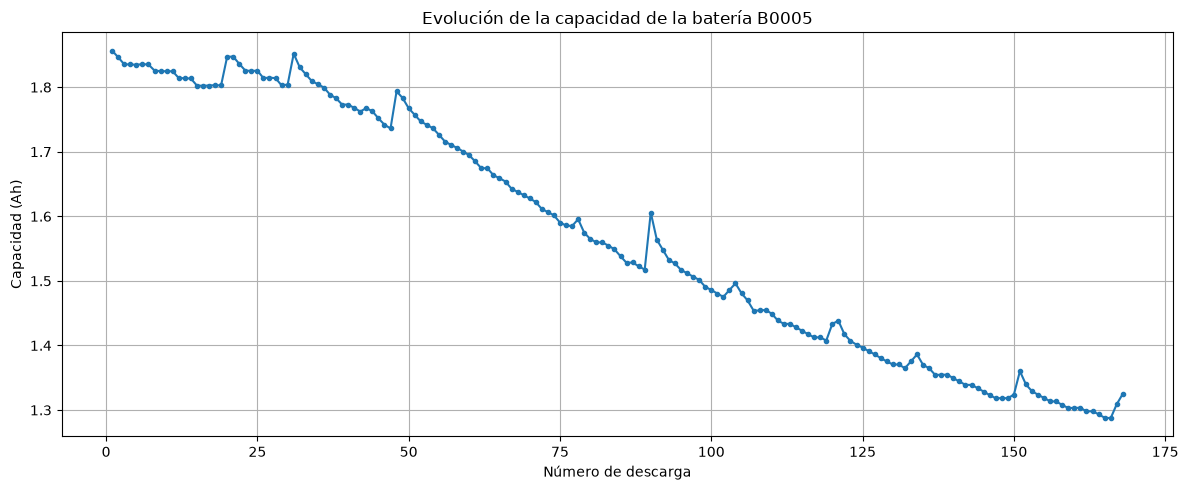

In [ ]:
# Represento la evolución de la capacidad
plt.figure(figsize=(12, 5))

plt.plot(
    tabla_capacidad["numero_descarga"],
    tabla_capacidad["capacidad_Ah"],
    marker="o",
    markersize=3,
    linestyle="-"
)

plt.title("Evolución de la capacidad de la batería B0005")
plt.xlabel("Número de descarga")
plt.ylabel("Capacidad (Ah)")
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretación de la gráfica 

En esta gráfica se representa la capacidad de la batería B0005 en Ah frente al número de descarga.

Se observa una tendencia general descendente. La capacidad comienza en aproximadamente 1,86 Ah y alcanza valores cercanos a 1,3 Ah en las últimas descargas.

La disminución no es completamente uniforme, ya que aparecen algunas fluctuaciones y recuperaciones puntuales entre ciclos.

Por tanto, la gráfica permite observar cómo evoluciona la capacidad real de la batería y muestra una pérdida global de capacidad a lo largo de los ensayos.


In [ ]:
# Calculo la capacidad relativa de cada descarga
tabla_capacidad["capacidad_relativa"] = (tabla_capacidad["capacidad_Ah"] / capacidad_inicial) * 100

In [ ]:
# Muestro la tabla completa de capacidades y porcentajes
display(tabla_capacidad[["numero_descarga", "capacidad_Ah", "capacidad_relativa"]])

,numero_descarga,capacidad_Ah,capacidad_relativa
0,1.0,1.856487,100.000000
1,2.0,1.846327,99.452721
2,3.0,1.835349,98.861386
3,4.0,1.835263,98.856718
4,5.0,1.834646,98.823482
...,...,...,...
163,164.0,1.293464,69.672630
164,165.0,1.288003,69.378514
165,166.0,1.287453,69.348842
166,167.0,1.309015,70.510328


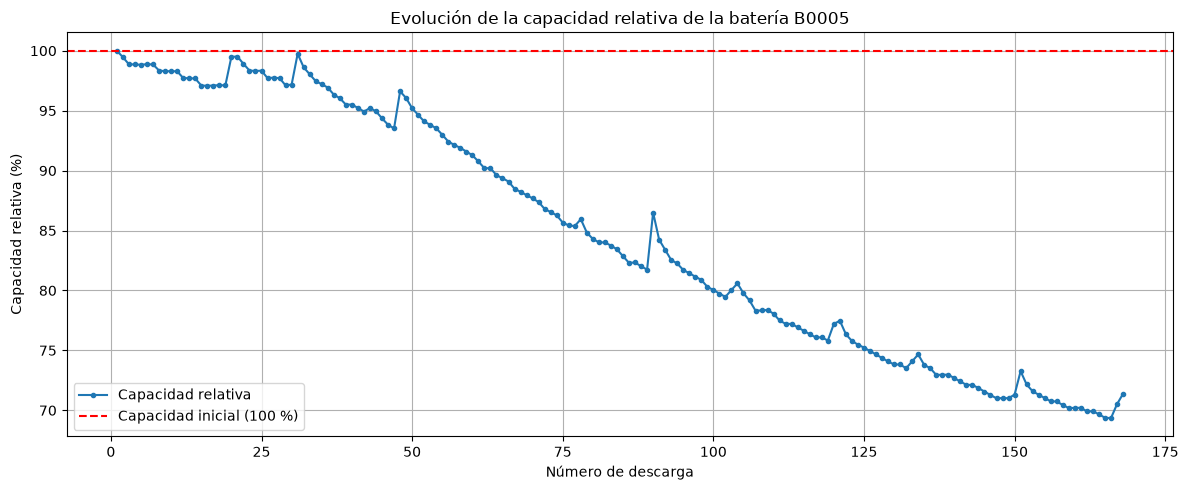

In [ ]:
# Represento la evolución de la capacidad relativa
plt.figure(figsize=(12, 5))

plt.plot(
    tabla_capacidad["numero_descarga"],
    tabla_capacidad["capacidad_relativa"],
    marker="o",
    markersize=3,
    linestyle="-",
    label="Capacidad relativa"
)

# Añado la referencia del 100 %
plt.axhline(
    y=100,
    color="red",
    linestyle="--",
    label="Capacidad inicial (100 %)"
)

plt.title("Evolución de la capacidad relativa de la batería B0005")
plt.xlabel("Número de descarga")
plt.ylabel("Capacidad relativa (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Interpretación de la gráfica 

En esta gráfica se representa la capacidad relativa de la batería respecto a la primera descarga, establecida como referencia del 100 %.

Esta representación permite observar directamente qué porcentaje de capacidad conserva la batería a medida que aumenta el número de descargas.

Se aprecia que la capacidad relativa disminuye progresivamente y que, en la última descarga, la batería conserva aproximadamente el 71,38 % de su capacidad inicial.

También aparecen algunas recuperaciones puntuales, especialmente al final de los ensayos. Sin embargo, estas no modifican la tendencia general descendente.


In [ ]:

# Obtengo la capacidad de la última descarga
capacidad_final = tabla_capacidad["capacidad_Ah"].iloc[-1]

# Calculo la diferencia absoluta
diferencia_capacidad = capacidad_inicial - capacidad_final

# Calculo la pérdida relativa
perdida_relativa = (diferencia_capacidad / capacidad_inicial) * 100

# Calculo el porcentaje de capacidad conservada
capacidad_conservada = 100 - perdida_relativa

# Creo una tabla resumen
resumen_degradacion = pd.DataFrame({"Indicador": ["Capacidad inicial (Ah)", "Capacidad final (Ah)",
    "Diferencia absoluta (Ah)","Pérdida relativa (%)","Capacidad conservada (%)"],
    "Resultado": [capacidad_inicial, capacidad_final, diferencia_capacidad, perdida_relativa,
    capacidad_conservada]})

display(resumen_degradacion)

,Indicador,Resultado
0,Capacidad inicial (Ah),1.856487
1,Capacidad final (Ah),1.325079
2,Diferencia absoluta (Ah),0.531408
3,Pérdida relativa (%),28.624384
4,Capacidad conservada (%),71.375616



### Interpretación del resumen numérico

La comparación entre la primera y la última descarga permite cuantificar la pérdida de capacidad de la batería a lo largo de los ensayos.

Los resultados muestran que la batería conserva aproximadamente el 71,38 % de su capacidad inicial después de las 168 descargas.

Esta diferencia confirma que la disminución observada en las gráficas no es únicamente una fluctuación puntual, sino que existe una pérdida global de capacidad durante el periodo analizado.


In [ ]:
# Selecciono las descargas estudiadas por Andrea
ciclos_andrea = tabla_capacidad[tabla_capacidad["numero_descarga"].isin([1, 80, 160])].copy()

# Muestro los datos para compararlos
display(ciclos_andrea[["numero_descarga", "capacidad_Ah", "capacidad_relativa", "duracion_s", "duracion_activa_s"]])

,numero_descarga,capacidad_Ah,capacidad_relativa,duracion_s,duracion_activa_s
0,1.0,1.856487,100.000000,3690.234,3311.234
79,80.0,1.564902,84.293703,3095.094,2794.047
159,160.0,1.303357,70.205558,2811.485,2326.219



### Relación entre la capacidad y la comparación de ciclos de Andrea

Para relacionar el análisis de degradación con la comparación de ciclos realizada por Andrea, se han seleccionado las descargas 1, 80 y 160.

Se observa que la capacidad disminuye desde 1,8565 Ah en la primera descarga hasta 1,5649 Ah en la descarga 80 y 1,3034 Ah en la descarga 160. Entre la primera y la descarga 160, esto supone una reducción de aproximadamente el 29,79 %.

También se observa una disminución de la duración activa, que pasa de 3311,23 segundos en la primera descarga a 2794,05 segundos en la descarga 80 y 2326,22 segundos en la descarga 160.

Por tanto, los resultados muestran que la disminución de capacidad coincide con una reducción de la duración activa en los tres ciclos seleccionados. Esta comparación complementa el análisis de las señales realizado por Andrea y permite relacionar los cambios temporales con la evolución de la capacidad.



## Conclusiones del análisis de degradación

A partir del análisis de las 168 descargas de la batería B0005, se observa una tendencia general descendente de su capacidad a medida que aumenta el número de descargas. Esta evolución es compatible con un proceso de degradación progresiva de la batería.

Sin embargo, la disminución no es completamente uniforme, ya que aparecen recuperaciones y fluctuaciones puntuales entre algunos ciclos. Por tanto, la capacidad no disminuye de manera constante durante todos los ensayos.

La comparación de las descargas 1, 80 y 160 muestra que la reducción de capacidad coincide con una disminución de la duración activa. Esta relación permite complementar el análisis de capacidad con los resultados obtenidos por Andrea en la comparación de ciclos.

En conjunto, los resultados sugieren una pérdida progresiva de capacidad durante los ensayos. No obstante, deben tenerse en cuenta las fluctuaciones observadas y las posibles diferencias en las condiciones experimentales, ya que los datos analizados no permiten atribuir todos los cambios exclusivamente al envejecimiento de la batería.